# 03 – Exploratory data analysis (EDA)
Non-graphical and graphical analysis of the integrated data. All charts are also saved in `outputs/` (for the presentation).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config
from src.db import get_connection

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
config.OUTPUT_DIR.mkdir(exist_ok=True)
conn = get_connection()
print("Database:", config.DB_PATH.relative_to(ROOT))
from src.features import load_analysis, WEEKDAYS
df = load_analysis(conn)
print(f"{len(df):,} arrivals at {df['bpuic'].nunique()} stations, {df['operating_day'].nunique()} days "
      f"({df['operating_day'].min()} to {df['operating_day'].max()})")

Database: data/train_delays.sqlite


400,135 arrivals at 100 stations, 13 days (2026-10-14 to 2026-10-27)


## 1. Non-graphical EDA

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400135 entries, 0 to 400134
Data columns (total 29 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   operating_day     400135 non-null  object        
 1   trip_id           400135 non-null  object        
 2   operator          400135 non-null  object        
 3   train_type        400135 non-null  object        
 4   line              400135 non-null  object        
 5   bpuic             400135 non-null  int64         
 6   station           400135 non-null  object        
 7   canton            400135 non-null  object        
 8   region            400135 non-null  object        
 9   lat               400135 non-null  float64       
 10  lon               400135 non-null  float64       
 11  arr_scheduled     400135 non-null  object        
 12  arr_delay_min     400135 non-null  float64       
 13  temperature       400135 non-null  float64       
 14  prec

In [3]:
display(df[["arr_delay_min", "temperature", "precipitation", "snowfall", "wind"]].describe().round(2).T)
display(df.isna().sum().to_frame("missing_values").query("missing_values > 0"))

,count,mean,std,min,25%,50%,75%,max
arr_delay_min,400135.0,0.76,2.69,-9.95,-0.23,0.4,1.18,173.15
temperature,400135.0,10.98,3.67,-0.10,8.60,10.5,13.00,28.20
precipitation,400135.0,0.20,0.49,0.00,0.00,0.0,0.10,7.50
snowfall,400135.0,0.00,0.02,0.00,0.00,0.0,0.00,1.47
wind,400135.0,6.84,6.25,0.00,2.20,4.5,9.90,35.50


,missing_values


In [4]:
print(f"Share late (>= {config.LATE_THRESHOLD_MIN:.0f} min): {df['late'].mean():.1%}")
for col in ["region", "time_window", "train_type_group", "operator_group", "weekday"]:
    t = (df.groupby(col, observed=True)
           .agg(arrivals=("late", "size"),
                share_late=("late", "mean"),
                mean_delay=("arr_delay_min", "mean"),
                median_delay=("arr_delay_min", "median"))
           .sort_values("arrivals", ascending=False))
    display(t.style.format({"share_late": "{:.1%}", "mean_delay": "{:.2f}",
                            "median_delay": "{:.2f}", "arrivals": "{:,}"}))

Share late (>= 3 min): 6.3%


,arrivals,share_late,mean_delay,median_delay
region,,,,
German-speaking,"321,461",5.8%,0.75,0.43
Romandy,"63,536",8.8%,0.77,0.17
Ticino,"15,138",7.1%,0.89,0.28


,arrivals,share_late,mean_delay,median_delay
time_window,,,,
Off-peak,"305,352",5.7%,0.67,0.32
Peak,"94,783",8.3%,1.02,0.65


,arrivals,share_late,mean_delay,median_delay
train_type_group,,,,
S-Bahn,"251,270",5.0%,0.65,0.43
InterRegio,"52,304",6.9%,0.73,0.32
Regio,"32,712",7.6%,0.63,0.18
RegioExpress,"29,910",6.6%,0.76,0.33
InterCity,"27,009",10.7%,1.01,0.40
International,"5,042",25.8%,5.23,0.90
Other,"1,888",15.5%,2.40,0.63


,arrivals,share_late,mean_delay,median_delay
operator_group,,,,
SBB,"270,014",7.7%,0.96,0.50
BLS-bls,"34,144",3.2%,0.56,0.40
THURBO,"29,748",3.5%,0.26,0.08
Other,"27,146",4.5%,0.35,0.13
SOB-sob,"20,386",3.7%,0.44,0.23
RBS,"14,718",1.7%,0.05,-0.07
AB-ab,"3,979",2.1%,-0.44,-0.53


,arrivals,share_late,mean_delay,median_delay
weekday,,,,
Thu,"62,825",5.8%,0.72,0.40
Wed,"62,789",8.4%,0.94,0.55
Fri,"62,493",7.8%,0.98,0.48
Tue,"62,490",5.3%,0.66,0.37
Sat,"59,419",6.1%,0.75,0.35
Sun,"57,747",5.0%,0.56,0.25
Mon,"32,372",4.9%,0.62,0.35


Cross table region × time window (share late) – directly via SQL from the database:

In [5]:
display(pd.read_sql("""
    SELECT region,
           ROUND(100.0 * AVG(CASE WHEN CAST(strftime('%H', arr_scheduled) AS INT) IN (6,7,8,16,17,18)
                                   AND strftime('%w', arr_scheduled) NOT IN ('0','6')
                                  THEN arr_delay_min >= 3 END), 1) AS peak_percent,
           ROUND(100.0 * AVG(CASE WHEN NOT (CAST(strftime('%H', arr_scheduled) AS INT) IN (6,7,8,16,17,18)
                                   AND strftime('%w', arr_scheduled) NOT IN ('0','6'))
                                  THEN arr_delay_min >= 3 END), 1) AS off_peak_percent
    FROM analysis GROUP BY region""", conn))

top10 = (df.groupby("station").agg(arrivals=("late", "size"), share_late=("late", "mean"))
           .query("arrivals >= 500").sort_values("share_late", ascending=False))
print("Stations with the highest share of late arrivals:")
display(top10.head(10).style.format({"share_late": "{:.1%}", "arrivals": "{:,}"}))

,region,peak_percent,off_peak_percent
0,German-speaking,8.1,5.0
1,Romandy,9.0,8.8
2,Ticino,8.3,6.7


Stations with the highest share of late arrivals:


,arrivals,share_late
station,,
Yverdon-les-Bains,"3,177",15.5%
Palézieux,"3,120",13.6%
Lausanne,"6,835",12.2%
Basel SBB,"5,736",12.1%
Renens VD,"6,334",11.9%
Biel/Bienne,"4,457",10.0%
Morges,"3,463",9.9%
Aigle,"3,639",9.6%
Montreux,"3,456",9.6%


## 2. Graphical EDA

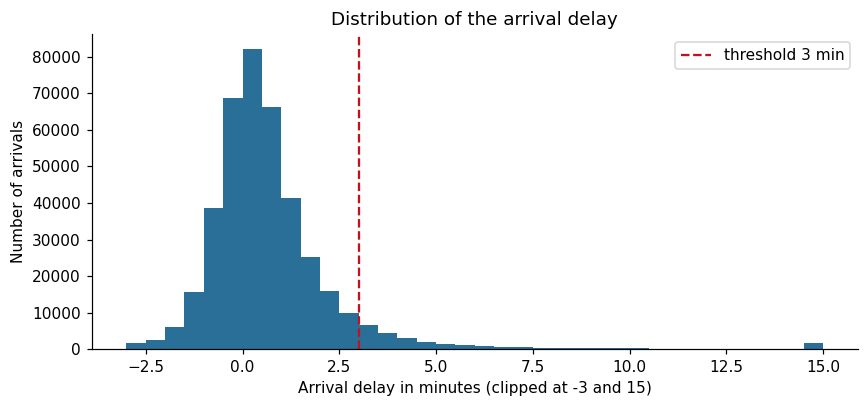

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(df["arr_delay_min"].clip(-3, 15), bins=np.arange(-3, 15.5, 0.5), color="#2a6f97")
ax.axvline(config.LATE_THRESHOLD_MIN, color="#c1121f", ls="--", label="threshold 3 min")
ax.set_xlabel("Arrival delay in minutes (clipped at -3 and 15)"); ax.set_ylabel("Number of arrivals")
ax.set_title("Distribution of the arrival delay"); ax.legend()
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "03_histogram_delay.png", dpi=200); plt.show()

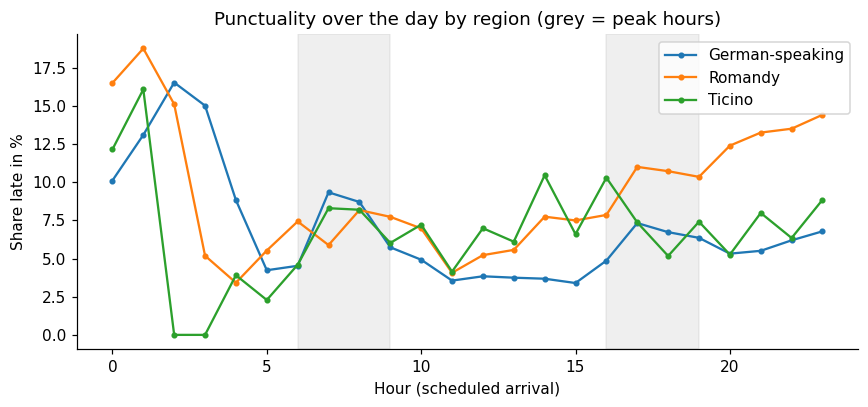

In [7]:
regions = [r for r in ["German-speaking", "Romandy", "Ticino"] if r in df["region"].unique()]
fig, ax = plt.subplots(figsize=(8, 3.8))
for r in regions:
    s = df[df["region"] == r].groupby("hour")["late"].mean()
    ax.plot(s.index, 100 * s.values, marker="o", ms=3, label=r)
for a, b in [(6, 9), (16, 19)]:
    ax.axvspan(a, b, color="grey", alpha=0.12)
ax.set_xlabel("Hour (scheduled arrival)"); ax.set_ylabel("Share late in %")
ax.set_title("Punctuality over the day by region (grey = peak hours)"); ax.legend()
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "03_delay_by_hour.png", dpi=200); plt.show()

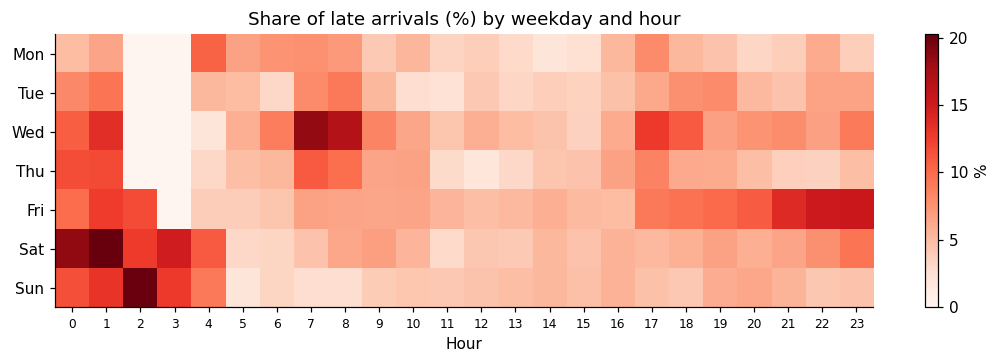

In [8]:
pivot = df.pivot_table(index="weekday", columns="hour", values="late", aggfunc="mean", observed=True) * 100
fig, ax = plt.subplots(figsize=(10, 3.4))
im = ax.imshow(pivot.values, aspect="auto", cmap="Reds")
ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index)
ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns, fontsize=8)
ax.set_xlabel("Hour"); ax.set_title("Share of late arrivals (%) by weekday and hour")
fig.colorbar(im, ax=ax, label="%")
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "03_heatmap_weekday_hour.png", dpi=200); plt.show()

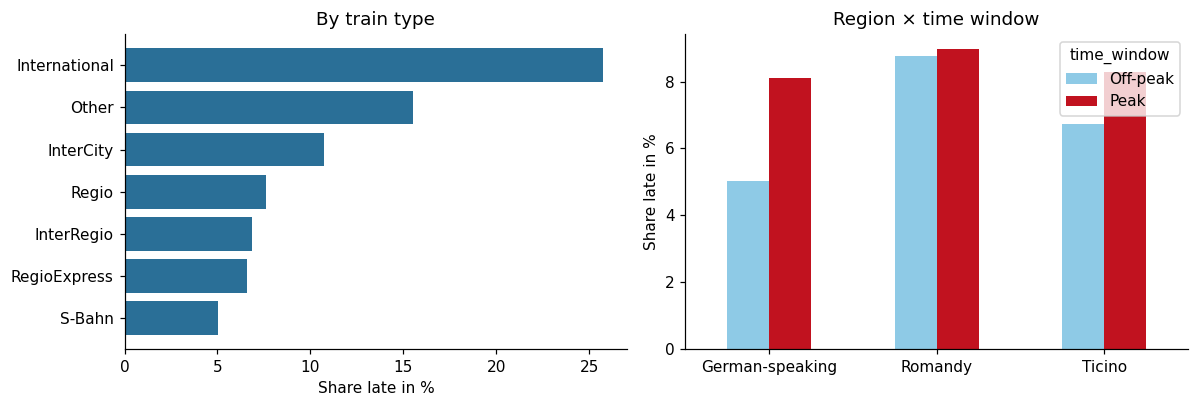

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
z = df.groupby("train_type_group")["late"].mean().sort_values() * 100
axes[0].barh(z.index, z.values, color="#2a6f97"); axes[0].set_xlabel("Share late in %"); axes[0].set_title("By train type")

grp = df.groupby(["region", "time_window"])["late"].mean().unstack() * 100
grp = grp.loc[[r for r in regions if r in grp.index], ["Off-peak", "Peak"]]
grp.plot(kind="bar", ax=axes[1], color=["#8ecae6", "#c1121f"], rot=0)
axes[1].set_ylabel("Share late in %"); axes[1].set_xlabel(""); axes[1].set_title("Region × time window")
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "03_train_type_region_time_window.png", dpi=200); plt.show()

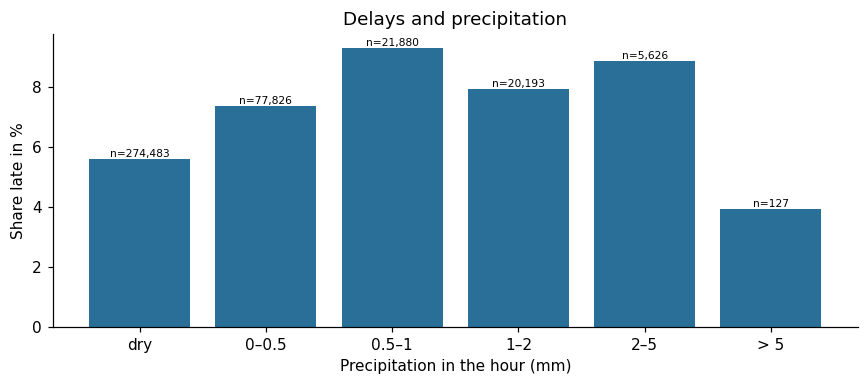

In [10]:
bins = [-0.01, 0.0, 0.5, 1, 2, 5, 100]
labels = ["dry", "0–0.5", "0.5–1", "1–2", "2–5", "> 5"]
df["rain_class"] = pd.cut(df["precipitation"].fillna(0), bins=bins, labels=labels)
r = df.groupby("rain_class", observed=True).agg(share=("late", "mean"), n=("late", "size"))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(r.index.astype(str), 100 * r["share"], color="#2a6f97")
for i, (a, n) in enumerate(zip(r["share"], r["n"])):
    ax.text(i, 100 * a, f"n={n:,}", ha="center", va="bottom", fontsize=7)
ax.set_xlabel("Precipitation in the hour (mm)"); ax.set_ylabel("Share late in %")
ax.set_title("Delays and precipitation")
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "03_precipitation.png", dpi=200); plt.show()

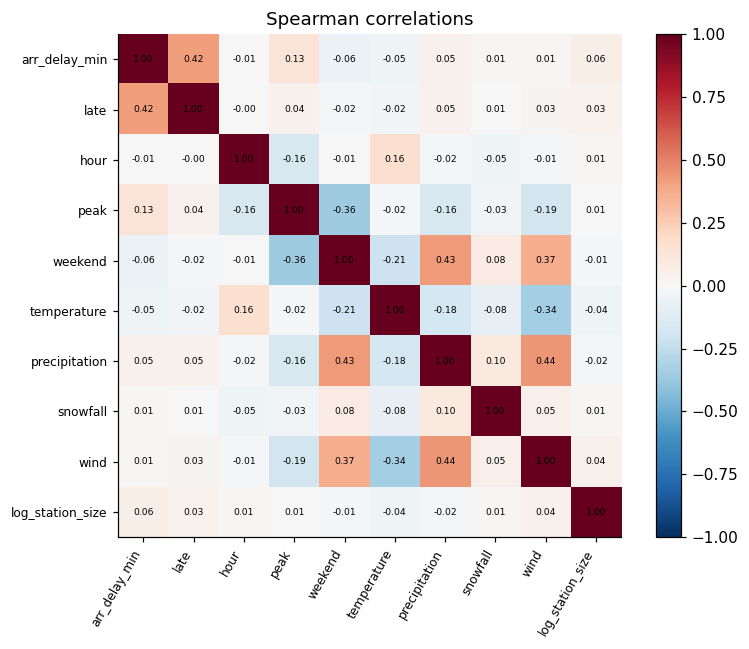

In [11]:
num = ["arr_delay_min", "late", "hour", "peak", "weekend", "temperature",
       "precipitation", "snowfall", "wind", "log_station_size"]
corr = df[num].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(num))); ax.set_yticklabels(num, fontsize=8)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax); ax.set_title("Spearman correlations")
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "03_correlations.png", dpi=200); plt.show()

## 3. Findings from the EDA
*(Real data 14–27 Oct 2026 without 19 Oct, 400,135 arrivals at the 100 largest stations)*
- **Distribution:** strongly right-skewed. Median 0.4 min, 93.7% of arrivals are below 3 min. Overall **6.3%** are late (≥ 3 min) → imbalanced classes, important for the model.
- **Time of day / peak hours:** German-speaking Switzerland shows clear peaks in the morning and evening rush hours (peak 8.1% vs. off-peak 5.0%). In **Romandy, by contrast, the share rises almost steadily over the day** (approx. 4% at 11:00 → more than 14% at 23:00); there is hardly any difference between peak and off-peak there (9.0% vs. 8.8%). High values at night (00:00–03:00) are based on few trains (weekend night services).
- **Weekday:** Wednesday (8.4%) and Friday (7.8%) are the worst, Monday (4.9%) the best. With only 2 weeks of data these may be single events.
- **Regions:** Romandy 8.8%, Ticino 7.1%, German-speaking Switzerland 5.8%. The mean delay is almost the same (0.75–0.89 min); the difference lies in the outliers.
- **Train type:** international trains 25.8%, InterCity 10.7%, S-Bahn only 5.0%. Long routes accumulate delay.
- **Weather:** with rain (≥ 0.1 mm/h) 7.8% vs. 5.6% without rain. There was practically no snow in October.